# Audit Data Analytics: step-by-step working
Run the cells top to bottom (Shift+Enter). Each step explains *why*, runs the code, then shows what it produced.

In Colab, first run a cell with: `!pip install openpyxl scipy`

In [1]:
"""Audit Data Analytics: Journal Entry & Accounts Payable testing (free, offline).
Pipeline: 1 data -> 2 validate -> 3 materiality -> 4 tests -> 5 risk score -> 6 sample -> 7 workbook."""
import numpy as np, pandas as pd
from scipy.stats import chisquare
from openpyxl import load_workbook
from openpyxl.chart import BarChart, LineChart, Reference
from openpyxl.styles import Font, PatternFill


rng = np.random.default_rng(42)
REVENUE = 50_000_000
APPROVAL_LIMIT = 10_000

## Step 1: Data
We create a synthetic client ledger and plant known anomalies (duplicates, round amounts, SoD breaches, splits, bad rows). A real extract would be loaded here instead.

In [2]:
n = 3000
amt = np.round(10 ** rng.uniform(1.5, 5.2, n), 2)                     # log-uniform => follows Benford
df = pd.DataFrame({
    "je_id": [f"JE{i:05d}" for i in range(n)],
    "posting_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), "D"),
    "vendor": rng.choice([f"V{i:03d}" for i in range(60)], n),
    "amount": amt,
    "created_by": rng.choice(["alice", "bob", "carol", "dan"], n),
})
df["approved_by"] = rng.choice(["mgr1", "mgr2"], n)
# inject known anomalies so every test has something to find
dup = df.sample(25, random_state=1).copy(); dup["je_id"] = [f"JE{n+i:05d}" for i in range(25)]
dup["posting_date"] += pd.Timedelta(days=2); df = pd.concat([df, dup], ignore_index=True)
idx = df.sample(40, random_state=2).index; df.loc[idx, "amount"] = rng.choice([5000, 10000, 20000, 50000], 40)  # round
idx = df.sample(30, random_state=3).index; df.loc[idx, "approved_by"] = df.loc[idx, "created_by"]               # SoD
split = pd.DataFrame({"je_id": [f"JE9{i:04d}" for i in range(12)], "posting_date": pd.Timestamp("2025-06-30"),
                      "vendor": "V007", "amount": 9_800.0, "created_by": "bob", "approved_by": "mgr1"})
df = pd.concat([df, split], ignore_index=True)
df.loc[df.sample(8, random_state=4).index, "posting_date"] = pd.NaT                                              # bad data
df["debit"] = df.amount; df["credit"] = df.amount
df.loc[df.sample(5, random_state=5).index, "credit"] -= 100                                                      # unbalanced


print(df.shape); df.head(10)

(3037, 8)


,je_id,posting_date,vendor,amount,created_by,approved_by,debit,credit
0,JE00000,2025-08-15,V026,23101.35,carol,mgr1,23101.35,23101.35
1,JE00001,2025-10-30,V001,1330.00,bob,mgr2,1330.00,1330.00
2,JE00002,2025-08-22,V040,47512.98,alice,mgr2,47512.98,47512.98
3,JE00003,2025-08-05,V027,12029.89,alice,mgr2,12029.89,12029.89
4,JE00004,2025-06-20,V046,70.54,carol,mgr2,70.54,70.54
5,JE00005,2025-03-31,V037,128766.44,carol,mgr1,128766.44,128766.44
6,JE00006,2025-04-13,V047,20711.75,carol,mgr1,20711.75,20711.75
7,JE00007,2025-09-30,V027,25611.67,alice,mgr1,25611.67,25611.67
8,JE00008,2025-01-26,V000,94.19,carol,mgr2,94.19,94.19
9,JE00009,2025-01-31,V007,1466.99,alice,mgr2,1466.99,1466.99


## Step 2: Data validation
Check completeness and integrity *before* testing. Rows with no date are excluded but reported.

In [3]:
val = {
    "Total rows": len(df),
    "Missing posting date": int(df.posting_date.isna().sum()),
    "Duplicate JE IDs": int(df.je_id.duplicated().sum()),
    "Unbalanced entries (debit != credit)": int((df.debit.round(2) != df.credit.round(2)).sum()),
    "Non-positive amounts": int((df.amount <= 0).sum()),
    "Total value": round(df.amount.sum(), 2),
}
clean = df.dropna(subset=["posting_date"]).copy()    # exclude unusable rows, but report them


pd.DataFrame(list(val.items()), columns=['Check','Value'])

,Check,Value
0,Total rows,3037.0
1,Missing posting date,8.0
2,Duplicate JE IDs,0.0
3,Unbalanced entries (debit != credit),5.0
4,Non-positive amounts,0.0
5,Total value,57593572.4


## Step 3: Materiality
Overall = 0.5% of revenue; performance = 75%; clearly trivial = 5%. Findings are ranked against these.

In [4]:
OM = 0.005 * REVENUE; PM = 0.75 * OM; CT = 0.05 * OM
mat = {"Overall materiality (0.5% revenue)": OM, "Performance materiality (75%)": PM, "Clearly trivial (5%)": CT}


pd.DataFrame(list(mat.items()), columns=['Materiality','Amount'])

,Materiality,Amount
0,Overall materiality (0.5% revenue),250000.0
1,Performance materiality (75%),187500.0
2,Clearly trivial (5%),12500.0


## Step 4: Tests (Benford, duplicates, round, weekend, SoD, splitting)
Each test targets one fraud/error risk. The tables below show the flagged entries; the chart compares actual vs expected first digits.

Benford p-value=0.0003, MAD=0.0086


Duplicates 35 flagged
Round 40 flagged
Weekend 821 flagged
SoD 30 flagged
Splitting 1 flagged


,je_id,vendor,amount,posting_date,gap
3020,JE03020,V003,8393.08,2025-03-23,2.0
3026,JE90001,V007,9800.00,2025-06-30,0.0
3027,JE90002,V007,9800.00,2025-06-30,0.0
3028,JE90003,V007,9800.00,2025-06-30,0.0
3029,JE90004,V007,9800.00,2025-06-30,0.0


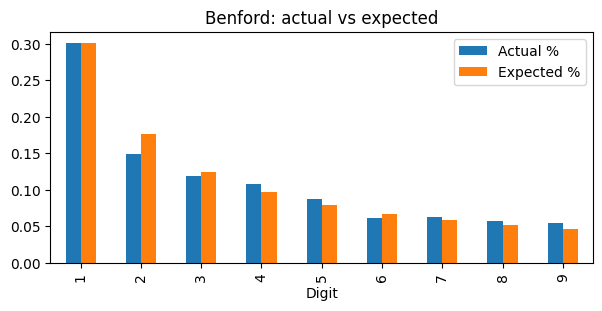

In [5]:
# T1 Benford first-digit
fd = clean.amount.astype(str).str.lstrip("0.").str[0].astype(int)
obs = fd.value_counts().reindex(range(1, 10), fill_value=0)
exp = np.log10(1 + 1 / np.arange(1, 10)) * len(fd)
chi, p = chisquare(obs, exp * obs.sum() / exp.sum())
mad = (np.abs(obs / obs.sum() - exp / exp.sum())).mean()
benford = pd.DataFrame({"Digit": range(1, 10), "Actual %": (obs / obs.sum()).values.round(4),
                        "Expected %": (exp / exp.sum()).round(4)})
# T2 Duplicate payments: same vendor + amount within 7 days
s = clean.sort_values(["vendor", "amount", "posting_date"]); g = s.groupby(["vendor", "amount"])
s["gap"] = g.posting_date.diff().dt.days
t_dup = s[(s.gap <= 7)][["je_id", "vendor", "amount", "posting_date", "gap"]]
# T3 Round-amount entries (>= 5,000 and multiple of 1,000)
t_round = clean[(clean.amount >= 5000) & (clean.amount % 1000 == 0)][["je_id", "vendor", "amount", "posting_date"]]
# T4 Weekend postings
t_wknd = clean[clean.posting_date.dt.dayofweek >= 5][["je_id", "vendor", "amount", "posting_date", "created_by"]]
# T5 Segregation of duties: creator == approver
t_sod = clean[clean.created_by == clean.approved_by][["je_id", "amount", "created_by", "approved_by"]]
# T6 Threshold splitting: same vendor/day, each below limit, together above it
d = clean[clean.amount < APPROVAL_LIMIT].groupby(["vendor", "posting_date"]).agg(count=("amount", "size"), total=("amount", "sum")).reset_index()
t_split = d[(d["count"] >= 2) & (d.total >= APPROVAL_LIMIT) & (d.total / d["count"] > 0.8 * APPROVAL_LIMIT)]


print(f'Benford p-value={p:.4f}, MAD={mad:.4f}')
benford.set_index('Digit').plot(kind='bar', title='Benford: actual vs expected', figsize=(7,3))
for n_, t_ in [('Duplicates',t_dup),('Round',t_round),('Weekend',t_wknd),('SoD',t_sod),('Splitting',t_split)]:
    print(n_, len(t_), 'flagged')
t_dup.head()

## Step 5: Risk score
Duplicates, SoD and splitting weigh 3; round and weekend weigh 1. One ranked list replaces six noisy ones.

In [6]:
w = {"dup": 3, "round": 1, "wknd": 1, "sod": 3, "split": 3}
clean["score"] = (clean.je_id.isin(t_dup.je_id) * w["dup"] + clean.je_id.isin(t_round.je_id) * w["round"]
                  + clean.je_id.isin(t_wknd.je_id) * w["wknd"] + clean.je_id.isin(t_sod.je_id) * w["sod"]
                  + clean.set_index(["vendor", "posting_date"]).index.isin(t_split.set_index(["vendor", "posting_date"]).index) * w["split"])
clean["above_PM"] = clean.amount >= PM
risky = clean[clean.score > 0].sort_values(["score", "amount"], ascending=False)


print(clean.score.value_counts().sort_index())
risky.head(10)

score
0    2124
1     832
2       7
3      40
4      15
6      11
Name: count, dtype: int64


,je_id,posting_date,vendor,amount,created_by,approved_by,debit,credit,score,above_PM
3026,JE90001,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3027,JE90002,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3028,JE90003,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3029,JE90004,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3030,JE90005,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3031,JE90006,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3032,JE90007,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3033,JE90008,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3034,JE90009,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False
3035,JE90010,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False


## Step 6: Sampling
All high-risk items (score >= 3) plus 25 random items with a fixed seed so anyone can reproduce the sample.

In [7]:
high = risky[risky.score >= 3]
rest = clean[~clean.je_id.isin(high.je_id)].sample(25, random_state=7)
sample = pd.concat([high.assign(basis="High risk (100%)"), rest.assign(basis="Random (seed 7)")])


print(sample.basis.value_counts())
sample.head(10)

basis
High risk (100%)    66
Random (seed 7)     25
Name: count, dtype: int64


,je_id,posting_date,vendor,amount,created_by,approved_by,debit,credit,score,above_PM,basis
3026,JE90001,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3027,JE90002,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3028,JE90003,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3029,JE90004,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3030,JE90005,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3031,JE90006,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3032,JE90007,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3033,JE90008,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3034,JE90009,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)
3035,JE90010,2025-06-30,V007,9800.0,bob,mgr1,9800.0,9800.0,6,False,High risk (100%)


## Step 7: Workbook and summary
Everything is written to an 11-sheet Excel file. This is the summary an audit team would read.

In [8]:
summary = pd.DataFrame([
    ("Benford chi-square p-value", round(p, 4), "p<0.05 => digits deviate from expectation (injected round amounts)"),
    ("Benford MAD", round(mad, 4), "<0.006 close, 0.006-0.012 acceptable, >0.012 nonconformity"),
    ("Possible duplicate payments", len(t_dup), "Confirm with invoices/bank"),
    ("Round-amount entries", len(t_round), "Inquire on business purpose"),
    ("Weekend postings", len(t_wknd), "Check authority/overrides"),
    ("SoD violations (creator = approver)", len(t_sod), "Control deficiency candidate"),
    ("Threshold-splitting groups", len(t_split), "Possible approval-limit circumvention"),
    ("Flagged entries above performance materiality", int(risky.above_PM.sum()), "Prioritise"),
], columns=["Test", "Result", "Interpretation"])
with pd.ExcelWriter("KPMG_style_JE_Testing.xlsx", engine="openpyxl") as xw:
    summary.to_excel(xw, sheet_name="Summary", index=False)
    pd.DataFrame(list(val.items()), columns=["Data validation", "Value"]).to_excel(xw, sheet_name="Data_Validation", index=False)
    pd.DataFrame(list(mat.items()), columns=["Materiality", "Amount"]).to_excel(xw, sheet_name="Materiality", index=False)
    benford.to_excel(xw, sheet_name="Benford", index=False)
    for name, t in [("Duplicates", t_dup), ("Round", t_round), ("Weekend", t_wknd), ("SoD", t_sod), ("Splitting", t_split)]:
        t.to_excel(xw, sheet_name=name, index=False)
    risky.head(200).to_excel(xw, sheet_name="Risk_Ranked", index=False)
    sample.to_excel(xw, sheet_name="Sample", index=False)
wb = load_workbook("KPMG_style_JE_Testing.xlsx")
for ws in wb:
    for c in ws[1]: c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="00338D")
    for col in ws.columns: ws.column_dimensions[col[0].column_letter].width = 24
ws = wb["Benford"]; ch = LineChart(); ch.title = "Benford: actual vs expected"
ch.add_data(Reference(ws, min_col=2, max_col=3, min_row=1, max_row=10), titles_from_data=True)
ch.set_categories(Reference(ws, min_col=1, min_row=2, max_row=10)); ws.add_chart(ch, "E2")
wb.save("KPMG_style_JE_Testing.xlsx")
print(summary.to_string(index=False)); print(val); print(mat)

summary

                                         Test   Result                                                     Interpretation
                   Benford chi-square p-value   0.0003 p<0.05 => digits deviate from expectation (injected round amounts)
                                  Benford MAD   0.0086         <0.006 close, 0.006-0.012 acceptable, >0.012 nonconformity
                  Possible duplicate payments  35.0000                                         Confirm with invoices/bank
                         Round-amount entries  40.0000                                        Inquire on business purpose
                             Weekend postings 821.0000                                          Check authority/overrides
          SoD violations (creator = approver)  30.0000                                       Control deficiency candidate
                   Threshold-splitting groups   1.0000                              Possible approval-limit circumvention
Flagged entries above pe

,Test,Result,Interpretation
0,Benford chi-square p-value,0.0003,p<0.05 => digits deviate from expectation (inj...
1,Benford MAD,0.0086,"<0.006 close, 0.006-0.012 acceptable, >0.012 n..."
2,Possible duplicate payments,35.0000,Confirm with invoices/bank
3,Round-amount entries,40.0000,Inquire on business purpose
4,Weekend postings,821.0000,Check authority/overrides
5,SoD violations (creator = approver),30.0000,Control deficiency candidate
6,Threshold-splitting groups,1.0000,Possible approval-limit circumvention
7,Flagged entries above performance materiality,0.0000,Prioritise
